# Budget grid with a frozen readout: the Pareto front

`runs/moo_zoom/dale_all_grid10x4_woutfrozen_150k`: a **10 × 4 grid** of (rate budget, wiring budget), cog20,
**W_out frozen** at its fan-in init (randn/√n_E; W_in, W_rec, biases train), 150k steps, 1 seed, batched.

The front is computed on this grid the same way as everywhere else (`cmc.front.compute_front`: maximise
min_task_acc, minimise metabolic and wiring cost, networks with min_task_acc < 0.6 excluded). For comparison:
the **trainable** cog20 NSGA-III front (`runs/moo/dale_all_nsga3_budget_p48g3_50k`, W_out trained, 50k steps).

In [1]:
import json
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import plotly.graph_objects as go
from cmc.front import FEASIBLE_MIN_TASK_ACC, compute_front
from cmc.paths import MOO_RUNS_DIR, MOO_ZOOM_RUNS_DIR
from cmc.task import rule_name

GRID_DIR = MOO_ZOOM_RUNS_DIR / "dale_all_grid10x4_woutfrozen_150k"
REF_DIR = MOO_RUNS_DIR / "dale_all_nsga3_budget_p48g3_50k"
OBJ = ("min_task_acc", "metabolic_cost", "wiring_cost")

g = pd.read_csv(GRID_DIR / "runs.csv")
args = json.loads((GRID_DIR / "summary.json").read_text())["args"]
TASKS = [c[4:] for c in g if c.startswith("acc_")]
g["is_feasible"] = g.min_task_acc >= FEASIBLE_MIN_TASK_ACC
g["is_pareto"], _ = compute_front(g.to_dict("records"), OBJ)
RB, CB = np.sort(g.rate_budget.unique()), np.sort(g.conn_budget.unique())

ref = pd.read_csv(REF_DIR / "runs.csv").drop_duplicates(["x0", "x1"]).reset_index(drop=True)
ref["is_feasible"] = ref.min_task_acc >= FEASIBLE_MIN_TASK_ACC
ref["is_pareto"], _ = compute_front(ref.to_dict("records"), OBJ)

print(f"grid: {len(g)} networks ({len(RB)} rate x {len(CB)} wiring budgets), {int(g.is_feasible.sum())} feasible, "
      f"{int(g.is_pareto.sum())} on its front | freeze={args['freeze']} w_out_init={args['w_out_init']} "
      f"steps={args['steps']} seeds={args['n_seeds']}")
print(f"trainable reference: {len(ref)} networks, {int(ref.is_feasible.sum())} feasible, {int(ref.is_pareto.sum())} on its front")

grid: 40 networks (10 rate x 4 wiring budgets), 17 feasible, 11 on its front | freeze=w_out w_out_init=fanin steps=150000 seeds=1
trainable reference: 144 networks, 118 feasible, 27 on its front


## 1. The grid: worst-task accuracy per budget pair
Rows: rate budget, columns: wiring budget. Bold box: on the grid's Pareto front; grey text: fails a task (< 0.6).

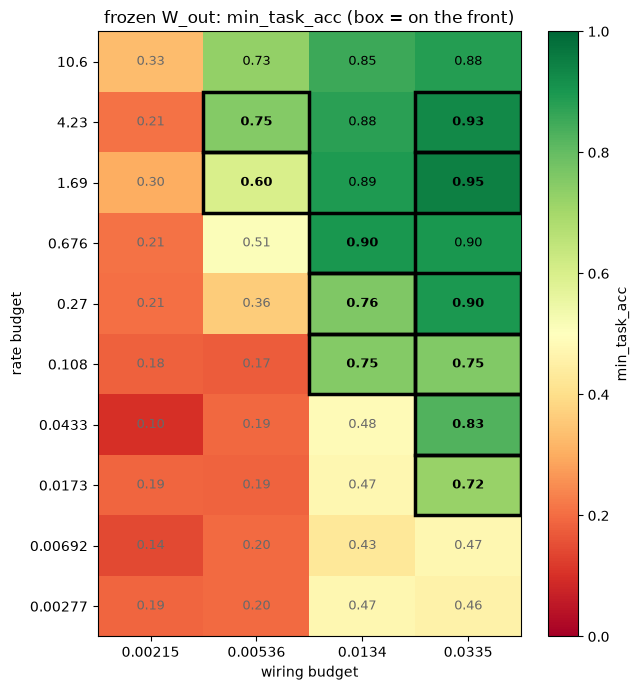

In [2]:
M = g.pivot_table(index="rate_budget", columns="conn_budget", values="min_task_acc").reindex(index=RB[::-1], columns=CB)
P = g.pivot_table(index="rate_budget", columns="conn_budget", values="is_pareto", aggfunc="max").reindex(index=RB[::-1], columns=CB)
fig, ax = plt.subplots(figsize=(6.5, 7))
im = ax.imshow(M.values, cmap="RdYlGn", vmin=0, vmax=1, aspect="auto")
for i in range(M.shape[0]):
    for j in range(M.shape[1]):
        v = M.values[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=9,
                color="black" if v >= FEASIBLE_MIN_TASK_ACC else "dimgrey", weight="bold" if P.values[i, j] else None)
        if P.values[i, j]:
            ax.add_patch(plt.Rectangle((j - 0.5, i - 0.5), 1, 1, fill=False, lw=2.5, ec="black"))
ax.set_xticks(range(len(CB))); ax.set_xticklabels([f"{c:.3g}" for c in CB])
ax.set_yticks(range(len(RB))); ax.set_yticklabels([f"{r:.3g}" for r in RB[::-1]])
ax.set_xlabel("wiring budget"); ax.set_ylabel("rate budget")
plt.colorbar(im, ax=ax, label="min_task_acc")
ax.set_title("frozen W_out: min_task_acc (box = on the front)"); plt.tight_layout(); plt.show()

## 2. Accuracy against each cost

Left: worst-task accuracy vs the **realised** metabolic cost, one line per wiring budget. Right: vs realised
wiring cost, one line per rate budget. Dashed: 0.6. Grey: the trainable front run's networks.

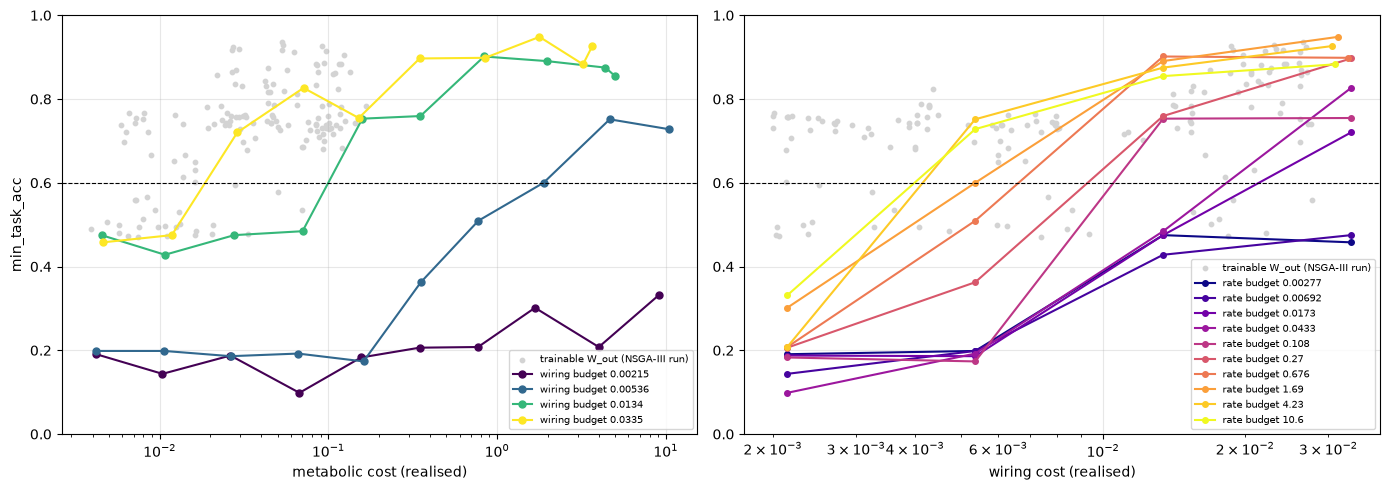

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
ax = axes[0]
ax.scatter(ref.metabolic_cost, ref.min_task_acc, s=10, c="lightgrey", label="trainable W_out (NSGA-III run)")
for i, cb in enumerate(CB):
    s = g[g.conn_budget == cb].sort_values("metabolic_cost")
    ax.plot(s.metabolic_cost, s.min_task_acc, "-o", ms=5, color=plt.cm.viridis(i / (len(CB) - 1)), label=f"wiring budget {cb:.3g}")
ax.set_xscale("log"); ax.set_xlabel("metabolic cost (realised)"); ax.set_ylabel("min_task_acc")
ax = axes[1]
ax.scatter(ref.wiring_cost, ref.min_task_acc, s=10, c="lightgrey", label="trainable W_out (NSGA-III run)")
for i, rb in enumerate(RB):
    s = g[g.rate_budget == rb].sort_values("wiring_cost")
    ax.plot(s.wiring_cost, s.min_task_acc, "-o", ms=4, color=plt.cm.plasma(i / (len(RB) - 1)), label=f"rate budget {rb:.3g}")
ax.set_xscale("log"); ax.set_xlabel("wiring cost (realised)")
for ax in axes:
    ax.axhline(FEASIBLE_MIN_TASK_ACC, color="k", ls="--", lw=0.8); ax.set_ylim(0, 1); ax.grid(alpha=0.3)
    ax.legend(fontsize=7, loc="lower right")
plt.tight_layout(); plt.show()

## 3. Were the budgets met?

Realised (eval) cost against the budget. On the diagonal = the budget binds; below = the network uses less
than allowed (budget not binding).

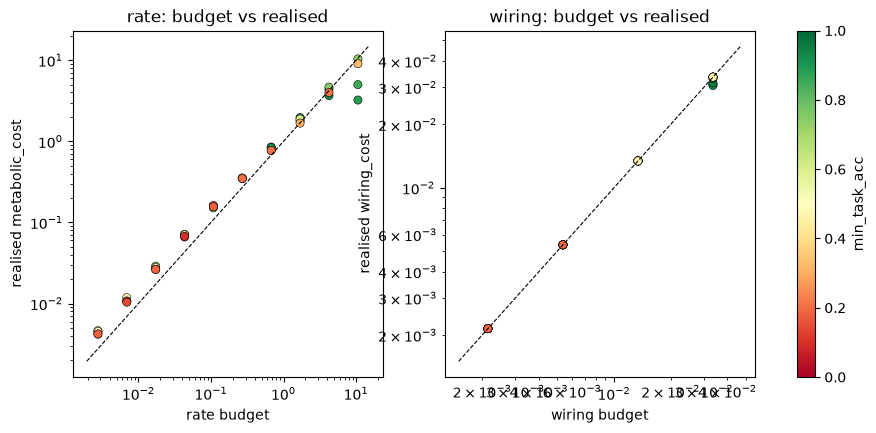

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, (b, c, lab) in zip(axes, [("rate_budget", "metabolic_cost", "rate"), ("conn_budget", "wiring_cost", "wiring")]):
    sc = ax.scatter(g[b], g[c], c=g.min_task_acc, cmap="RdYlGn", vmin=0, vmax=1, s=35, edgecolors="k", lw=0.4)
    lim = [min(g[b].min(), g[c].min()) * 0.7, max(g[b].max(), g[c].max()) * 1.4]
    ax.plot(lim, lim, "k--", lw=0.8); ax.set_xscale("log"); ax.set_yscale("log")
    ax.set_xlabel(f"{lab} budget"); ax.set_ylabel(f"realised {c}"); ax.set_title(f"{lab}: budget vs realised")
fig.colorbar(sc, ax=axes, label="min_task_acc"); plt.show()

## 4. The front (3D, interactive)

Grid networks coloured by accuracy (x = fails a task), the grid's front as a surface (Viridis) and big
markers; the trainable front run in light grey, its front as light-blue dots. Orange plane: 0.6.

In [5]:
def xyz(s):
    return dict(x=np.log10(s.metabolic_cost), y=np.log10(s.wiring_cost), z=s.min_task_acc)

def hov(s):
    return [f"rate budget {r.rate_budget:.3g}, wiring budget {r.conn_budget:.3g}<br>min_task_acc={r.min_task_acc:.3f} "
            f"mean={r.mean_acc:.3f}<br>metabolic={r.metabolic_cost:.4g} wiring={r.wiring_cost:.4g} conn_frac={r.conn_frac:.3f}"
            for r in s.itertuples()]

gf, gb = g[g.is_feasible], g[~g.is_feasible]
gp = g[g.is_pareto]
traces = [
    go.Scatter3d(**xyz(ref), mode="markers", name="trainable run (all)", marker=dict(size=2, color="lightgrey"), hoverinfo="skip"),
    go.Scatter3d(**xyz(ref[ref.is_pareto]), mode="markers", name="trainable front", marker=dict(size=3, color="#9ecae1"), hoverinfo="skip"),
    go.Scatter3d(**xyz(gb), mode="markers", name="frozen W_out: fails a task", hovertext=hov(gb), hoverinfo="text",
                 marker=dict(size=4, symbol="x", color=gb.min_task_acc, colorscale="RdYlGn", cmin=0, cmax=1)),
    go.Scatter3d(**xyz(gf), mode="markers", name="frozen W_out: feasible", hovertext=hov(gf), hoverinfo="text",
                 marker=dict(size=5, color=gf.min_task_acc, colorscale="RdYlGn", cmin=0, cmax=1,
                             colorbar=dict(title="min_task_acc", x=1.02, len=0.6))),
    go.Scatter3d(**xyz(gp), mode="markers", name=f"frozen W_out front ({len(gp)})", hovertext=hov(gp), hoverinfo="text",
                 marker=dict(size=9, color="black", symbol="diamond-open")),
]
if len(gp) >= 3:
    traces.append(go.Mesh3d(**xyz(gp), delaunayaxis="z", intensity=gp.min_task_acc, colorscale="Viridis", cmin=0, cmax=1,
                            opacity=0.45, name="frozen W_out front surface", showlegend=True, showscale=False, hoverinfo="skip"))
allx, ally = np.log10(pd.concat([g.metabolic_cost, ref.metabolic_cost])), np.log10(pd.concat([g.wiring_cost, ref.wiring_cost]))
traces.append(go.Surface(x=[allx.min(), allx.max()], y=[ally.min(), ally.max()], z=[[FEASIBLE_MIN_TASK_ACC] * 2] * 2,
                         colorscale=[[0, "orange"], [1, "orange"]], opacity=0.2, showscale=False,
                         name="min_task_acc = 0.6", showlegend=True, hoverinfo="skip"))
fig = go.Figure(traces)
fig.update_layout(title="Frozen-W_out grid vs trainable cog20 front",
                  scene=dict(xaxis_title="log10(metabolic cost)", yaxis_title="log10(wiring cost)",
                             zaxis_title="min_task_acc", zaxis=dict(range=[0, 1]), aspectmode="cube"),
                  width=980, height=740, legend=dict(x=0.0, y=1.0))
fig.show()

## 5. The front networks
Grid networks on its Pareto front, sorted by wiring cost, and their per-task accuracy (Yang display names).

,rate_budget,conn_budget,min_task_acc,mean_acc,metabolic_cost,wiring_cost,conn_frac
6,4.2300,0.0054,0.7516,0.9658,4.6472,0.0054,0.0169
10,1.6900,0.0054,0.6000,0.8980,1.8835,0.0054,0.0060
13,0.6760,0.0134,0.9016,0.9884,0.8365,0.0134,0.1345
17,0.2700,0.0134,0.7594,0.9757,0.3510,0.0134,0.0956
21,0.1080,0.0134,0.7531,0.9762,0.1589,0.0134,0.0405
4,4.2300,0.0335,0.9266,0.9905,3.6641,0.0306,0.6567
8,1.6900,0.0335,0.9484,0.9938,1.7820,0.0314,0.6445
20,0.1080,0.0335,0.7547,0.9819,0.1513,0.0335,0.4799
16,0.2700,0.0335,0.8969,0.9920,0.3474,0.0335,0.5917
24,0.0433,0.0335,0.8266,0.9845,0.0712,0.0335,0.2948


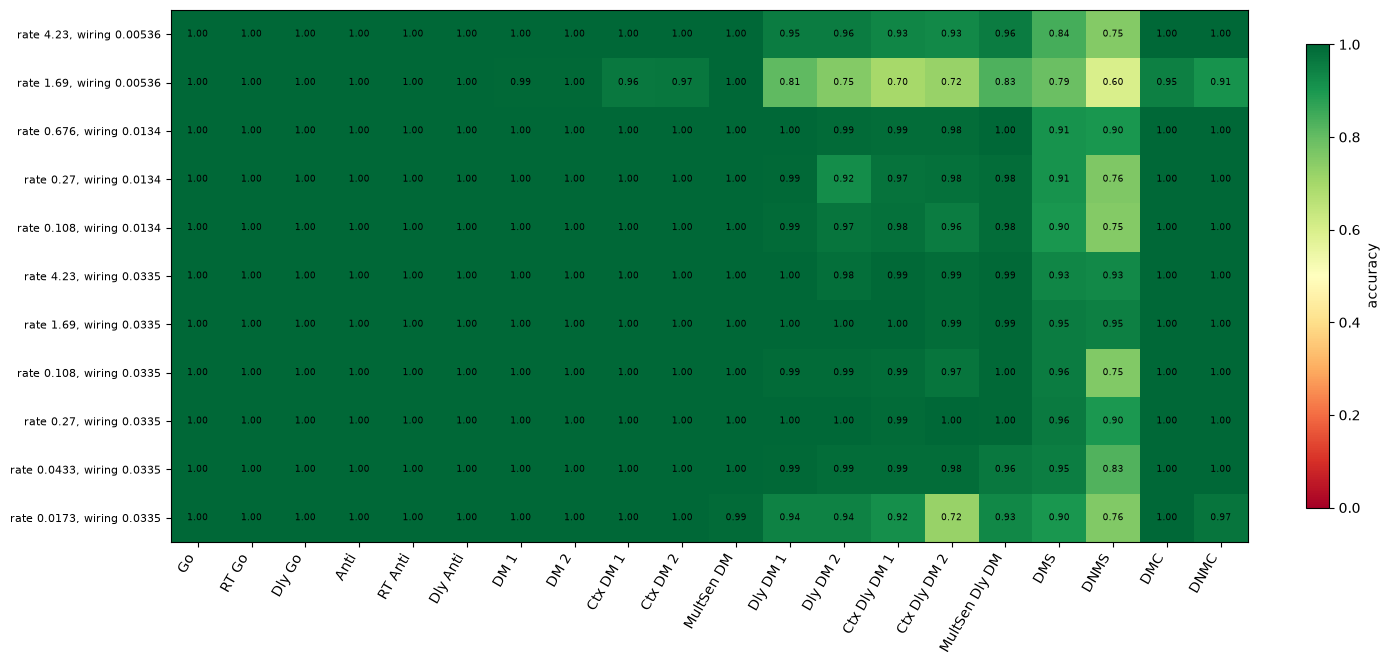

In [6]:
front = gp.sort_values(["wiring_cost", "metabolic_cost"])
display(front[["rate_budget", "conn_budget", "min_task_acc", "mean_acc", "metabolic_cost", "wiring_cost", "conn_frac"]].round(4))
A = front[[f"acc_{t}" for t in TASKS]].values
fig, ax = plt.subplots(figsize=(14, 0.45 * len(A) + 1.8))
im = ax.imshow(A, cmap="RdYlGn", vmin=0, vmax=1, aspect="auto")
ax.set_xticks(range(len(TASKS))); ax.set_xticklabels([rule_name[t] for t in TASKS], rotation=60, ha="right")
ax.set_yticks(range(len(A))); ax.set_yticklabels([f"rate {r:.3g}, wiring {c:.3g}" for r, c in zip(front.rate_budget, front.conn_budget)], fontsize=8)
for i in range(A.shape[0]):
    for j in range(A.shape[1]):
        ax.text(j, i, f"{A[i, j]:.2f}", ha="center", va="center", fontsize=6.5)
plt.colorbar(im, ax=ax, label="accuracy", fraction=0.02); plt.tight_layout(); plt.show()

# 6. Average task accuracy (mean over the 20 tasks)

Same grid with **mean_acc** next to min_task_acc. Two fronts: solid box = the front above (task axis =
min_task_acc), dashed box = the front with **mean_acc** as the task axis (`compute_front` with
`("mean_acc", "metabolic_cost", "wiring_cost")`; feasibility is still min_task_acc ≥ 0.6, as everywhere).

grid: 11 on the min-acc front, 12 on the mean-acc front, 11 on both


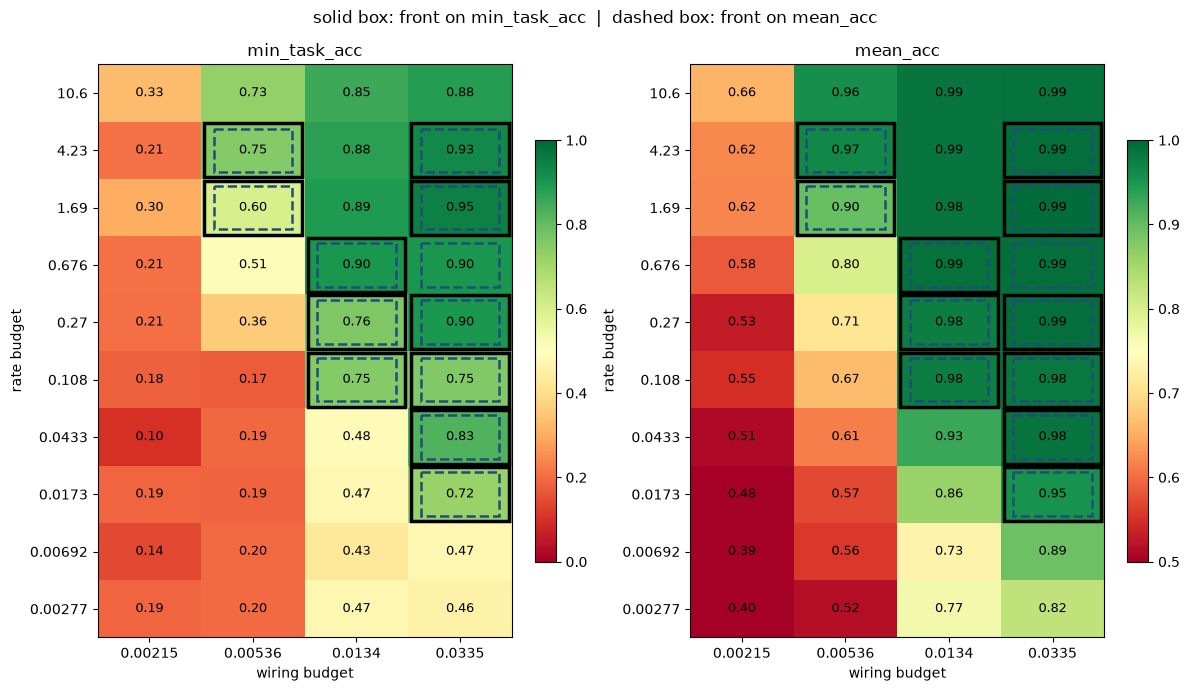

In [7]:
g["is_pareto_mean"], _ = compute_front(g.to_dict("records"), ("mean_acc", "metabolic_cost", "wiring_cost"))
ref["is_pareto_mean"], _ = compute_front(ref.to_dict("records"), ("mean_acc", "metabolic_cost", "wiring_cost"))
print(f"grid: {int(g.is_pareto.sum())} on the min-acc front, {int(g.is_pareto_mean.sum())} on the mean-acc front, "
      f"{int((g.is_pareto & g.is_pareto_mean).sum())} on both")

def grid(col):
    return g.pivot_table(index="rate_budget", columns="conn_budget", values=col, aggfunc="max").reindex(index=RB[::-1], columns=CB)

Pmin, Pmean = grid("is_pareto"), grid("is_pareto_mean")
fig, axes = plt.subplots(1, 2, figsize=(12, 7))
for ax, col, vmin in zip(axes, ["min_task_acc", "mean_acc"], [0, 0.5]):
    M = grid(col)
    im = ax.imshow(M.values, cmap="RdYlGn", vmin=vmin, vmax=1, aspect="auto")
    for i in range(M.shape[0]):
        for j in range(M.shape[1]):
            ax.text(j, i, f"{M.values[i, j]:.2f}", ha="center", va="center", fontsize=9)
            if Pmin.values[i, j]:
                ax.add_patch(plt.Rectangle((j - 0.47, i - 0.47), 0.94, 0.94, fill=False, lw=2.5, ec="black"))
            if Pmean.values[i, j]:
                ax.add_patch(plt.Rectangle((j - 0.38, i - 0.38), 0.76, 0.76, fill=False, lw=1.8, ec="#1f4e79", ls="--"))
    ax.set_xticks(range(len(CB))); ax.set_xticklabels([f"{c:.3g}" for c in CB])
    ax.set_yticks(range(len(RB))); ax.set_yticklabels([f"{r:.3g}" for r in RB[::-1]])
    ax.set_xlabel("wiring budget"); ax.set_ylabel("rate budget"); ax.set_title(col)
    plt.colorbar(im, ax=ax, fraction=0.046)
fig.suptitle("solid box: front on min_task_acc  |  dashed box: front on mean_acc"); plt.tight_layout(); plt.show()

## 6.1 Mean accuracy against each cost
As section 2, with mean_acc. Grey: the trainable front run.

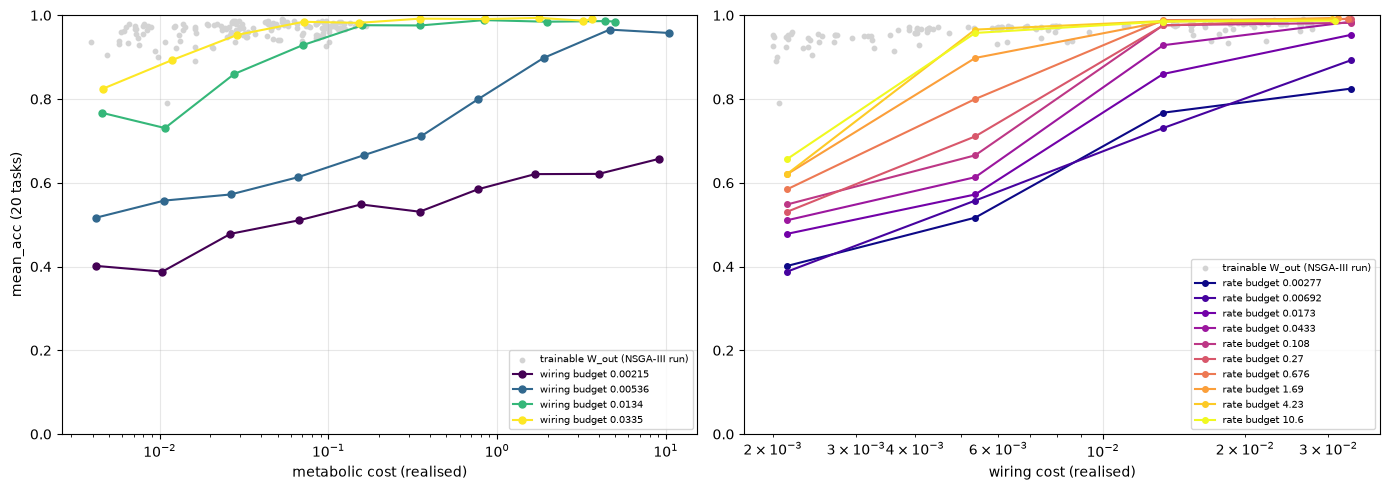

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
ax = axes[0]
ax.scatter(ref.metabolic_cost, ref.mean_acc, s=10, c="lightgrey", label="trainable W_out (NSGA-III run)")
for i, cb in enumerate(CB):
    s = g[g.conn_budget == cb].sort_values("metabolic_cost")
    ax.plot(s.metabolic_cost, s.mean_acc, "-o", ms=5, color=plt.cm.viridis(i / (len(CB) - 1)), label=f"wiring budget {cb:.3g}")
ax.set_xscale("log"); ax.set_xlabel("metabolic cost (realised)"); ax.set_ylabel("mean_acc (20 tasks)")
ax = axes[1]
ax.scatter(ref.wiring_cost, ref.mean_acc, s=10, c="lightgrey", label="trainable W_out (NSGA-III run)")
for i, rb in enumerate(RB):
    s = g[g.rate_budget == rb].sort_values("wiring_cost")
    ax.plot(s.wiring_cost, s.mean_acc, "-o", ms=4, color=plt.cm.plasma(i / (len(RB) - 1)), label=f"rate budget {rb:.3g}")
ax.set_xscale("log"); ax.set_xlabel("wiring cost (realised)")
for ax in axes:
    ax.set_ylim(0, 1); ax.grid(alpha=0.3); ax.legend(fontsize=7, loc="lower right")
plt.tight_layout(); plt.show()

## 6.2 Front networks, both accuracies
Union of the two fronts, sorted by wiring then metabolic cost.

In [9]:
both = g[g.is_pareto | g.is_pareto_mean].sort_values(["wiring_cost", "metabolic_cost"])
display(both[["rate_budget", "conn_budget", "min_task_acc", "mean_acc", "metabolic_cost", "wiring_cost",
              "conn_frac", "is_pareto", "is_pareto_mean"]]
        .rename(columns={"is_pareto": "front (min)", "is_pareto_mean": "front (mean)"}).round(4))
print(f"trainable front run, feasible networks: mean_acc {ref[ref.is_feasible].mean_acc.min():.3f}-"
      f"{ref[ref.is_feasible].mean_acc.max():.3f}; frozen-W_out grid, feasible: "
      f"{g[g.is_feasible].mean_acc.min():.3f}-{g[g.is_feasible].mean_acc.max():.3f}")

,rate_budget,conn_budget,min_task_acc,mean_acc,metabolic_cost,wiring_cost,conn_frac,front (min),front (mean)
6,4.2300,0.0054,0.7516,0.9658,4.6472,0.0054,0.0169,True,True
10,1.6900,0.0054,0.6000,0.8980,1.8835,0.0054,0.0060,True,True
13,0.6760,0.0134,0.9016,0.9884,0.8365,0.0134,0.1345,True,True
17,0.2700,0.0134,0.7594,0.9757,0.3510,0.0134,0.0956,True,True
21,0.1080,0.0134,0.7531,0.9762,0.1589,0.0134,0.0405,True,True
4,4.2300,0.0335,0.9266,0.9905,3.6641,0.0306,0.6567,True,True
8,1.6900,0.0335,0.9484,0.9938,1.7820,0.0314,0.6445,True,True
12,0.6760,0.0335,0.8984,0.9910,0.8495,0.0330,0.6352,False,True
20,0.1080,0.0335,0.7547,0.9819,0.1513,0.0335,0.4799,True,True
16,0.2700,0.0335,0.8969,0.9920,0.3474,0.0335,0.5917,True,True


trainable front run, feasible networks: mean_acc 0.925-0.990; frozen-W_out grid, feasible: 0.898-0.994


## 6.3 Both accuracies in cost space

Every network at its **realised** (metabolic, wiring) cost, shown as **two dots side by side**: left =
min_task_acc, right = mean_acc, same colour scale. Black ring: on the front (min_task_acc); x under the pair:
fails a task. Grey: the trainable front run, for reference.

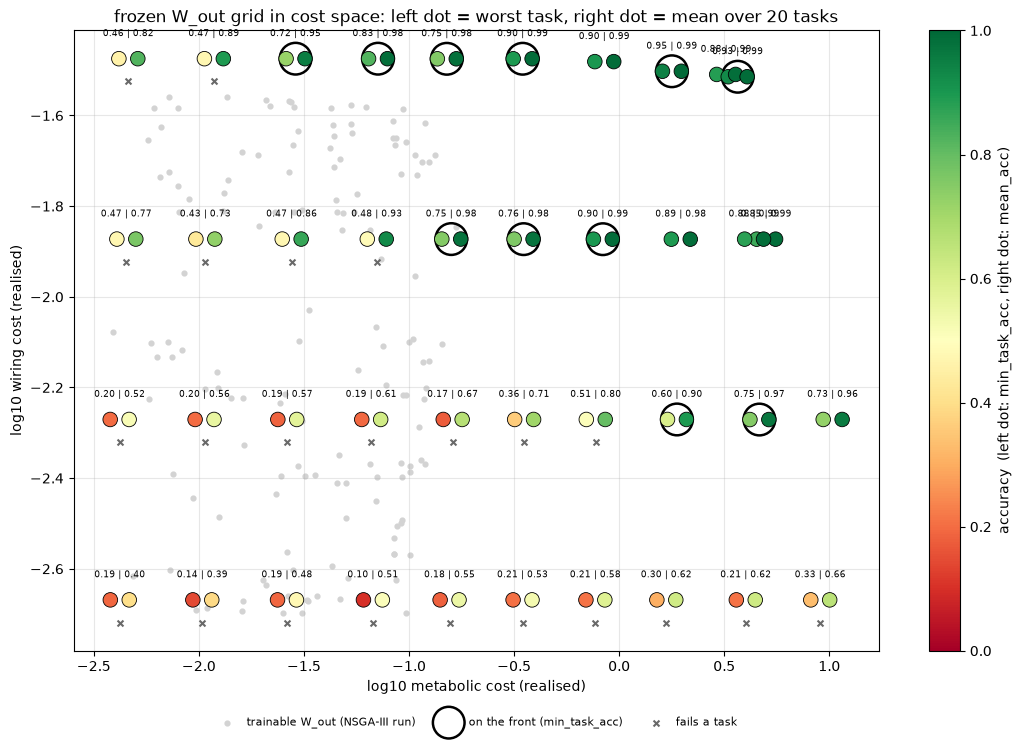

In [10]:
from matplotlib.colors import Normalize
cm, nrm = plt.cm.RdYlGn, Normalize(0, 1)
OFF = 0.045                                    # horizontal half-gap between the two dots, in log10 units
lx, ly = np.log10(g.metabolic_cost), np.log10(g.wiring_cost)

fig, ax = plt.subplots(figsize=(11, 7.5))
ax.scatter(np.log10(ref.metabolic_cost), np.log10(ref.wiring_cost), s=12, c="lightgrey", zorder=1,
           label="trainable W_out (NSGA-III run)")
ax.scatter(lx - OFF, ly, s=110, c=g.min_task_acc, cmap=cm, norm=nrm, edgecolors="k", lw=0.6, zorder=3)
ax.scatter(lx + OFF, ly, s=110, c=g.mean_acc, cmap=cm, norm=nrm, edgecolors="k", lw=0.6, zorder=3)
fr_ = g[g.is_pareto]
ax.scatter(np.log10(fr_.metabolic_cost), np.log10(fr_.wiring_cost), s=520, facecolors="none", edgecolors="k",
           lw=1.8, zorder=2, label="on the front (min_task_acc)")
bad = g[~g.is_feasible]
ax.scatter(lx[~g.is_feasible], ly[~g.is_feasible] - 0.05, s=18, marker="x", c="dimgrey", zorder=4, label="fails a task")
for r, x_, y_ in zip(g.itertuples(), lx, ly):
    ax.text(x_, y_ + 0.045, f"{r.min_task_acc:.2f} | {r.mean_acc:.2f}", ha="center", va="bottom", fontsize=6.5)
sm = plt.cm.ScalarMappable(norm=nrm, cmap=cm)
fig.colorbar(sm, ax=ax, label="accuracy  (left dot: min_task_acc, right dot: mean_acc)")
ax.set_xlabel("log10 metabolic cost (realised)"); ax.set_ylabel("log10 wiring cost (realised)")
ax.set_title("frozen W_out grid in cost space: left dot = worst task, right dot = mean over 20 tasks")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.09), ncol=3, fontsize=8, frameon=False); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()